## Model versus data
Does the fitted model reproduce the inning pattern it was not fit to?

In [ ]:
from abs_common import *           

                                     quantity observed model
                        Two left, innings 1-3    60.7% 50.6%
                        Two left, innings 8-9    40.4% 44.9%
                    Early minus late (points)     20.3   5.7
                        One left, innings 8-9    47.4% 47.1%
One-left minus two-left, innings 8-9 (points)      7.0   2.1


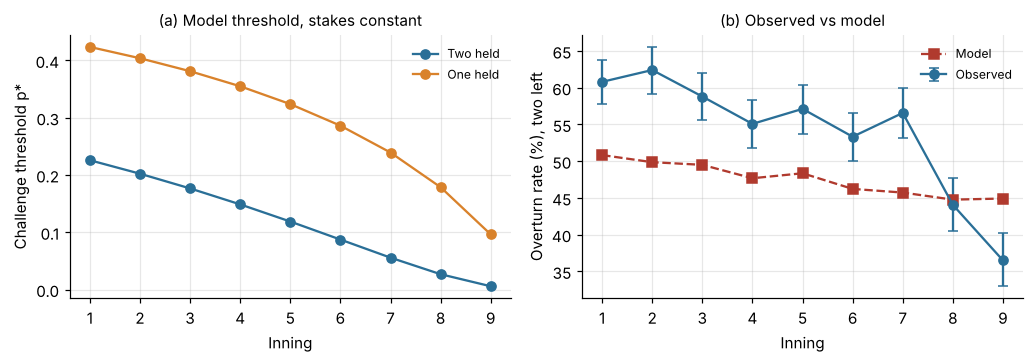

In [ ]:
run = game_model_run(); BASE = run["base"]; FIGSIM = run["fig"]   
def rate_mask(s, mask): return s["ok"][mask].mean()
two, one = BASE["k"] == 2, BASE["k"] == 1
inn_b = BASE["inn"]
m_early2 = rate_mask(BASE, two & (inn_b <= 3)); m_late2 = rate_mask(BASE, two & (inn_b >= 8))
m_late1 = rate_mask(BASE, one & (inn_b >= 8))
o_early2, o_late2 = ke/ne, kl/nl
k1l, n1l = reg.loc[8:9].k1.sum(), reg.loc[8:9].n1.sum()
o_late1 = k1l / n1l

cmp_tbl = pd.DataFrame([
    ("Two left, innings 1-3", pct(o_early2), pct(m_early2)),
    ("Two left, innings 8-9", pct(o_late2),  pct(m_late2)),
    ("Early minus late (points)", f"{100*(o_early2-o_late2):.1f}", f"{100*(m_early2-m_late2):.1f}"),
    ("One left, innings 8-9", pct(o_late1), pct(m_late1)),
    ("One-left minus two-left, innings 8-9 (points)", f"{100*(o_late1-o_late2):.1f}", f"{100*(m_late1-m_late2):.1f}"),
], columns=["quantity","observed","model"])
print(cmp_tbl.to_string(index=False))

# Figure: model threshold and observed vs model by inning
W1, D1 = solve(R_FIT, MU_FIT, 1.0)
start = [T - (i-1)*S for i in range(1, 10)]
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for kk, c, lab in ((2, BLUE, "Two held"), (1, ORANGE, "One held")):
    ax[0].plot(range(1, 10), [D1[kk, t]/(1 + D1[kk, t]) for t in start], "o-", color=c, label=lab)
ax[0].set_xlabel("Inning"); ax[0].set_ylabel("Challenge threshold p*"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("(a) Model threshold, stakes constant", fontsize=10)
r2 = reg.k2/reg.n2; ci2 = np.array([wilson(a, b) for a, b in zip(reg.k2, reg.n2)])
ax[1].errorbar(range(1, 10), 100*r2, yerr=[100*(r2-ci2[:,0]), 100*(ci2[:,1]-r2)], fmt="o-", color=BLUE, capsize=3, label="Observed")
ax[1].plot(range(1, 10), [100*rate_mask(FIGSIM, (FIGSIM["k"] == 2) & (FIGSIM["inn"] == i)) for i in range(1, 10)], "s--", color=RED, label="Model")
ax[1].set_xlabel("Inning"); ax[1].set_ylabel("Overturn rate (%), two left"); ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title("(b) Observed vs model", fontsize=10)
plt.tight_layout()